# Faz 3 - Derin Öğrenme Modelleri (LSTM ve CNN-LSTM)

İki model, 3 seed ile GPU'da eğitilmiştir. Bu notebook eğitimi tekrarlamaz; kayıtlı kayıp geçmişlerini ve metrik tablolarını okur.

In [1]:
import sys, json, glob, subprocess
from pathlib import Path
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'src').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src import config, models
config.apply_plot_style()
print(config.summary())

Yıllar: 2015-2016
Ham parquet: C:\Users\user\Desktop\merve\data\raw\pvdaq_sys4_2015_2016.parquet
Bölme: train 1 segment, val 6 segment, test 6 segment; veri sonu 2016-12-13 00:00
Hedef: ac_power [W]
Kapasite: 1.0 kW = 1000.0 W (nRMSE paydası: CAPACITY_W)


## 1. Mimari ve parametre sayısı

In [2]:
rows = []
for n in ('lstm', 'cnn_lstm'):
    m = models.build_model(n)
    print(m)
    rows.append({'model': n, 'parametre': models.count_params(m)})
print(pd.DataFrame(rows).to_string(index=False))

LSTMNet(
  (rnn): LSTM(9, 64, num_layers=2, batch_first=True, dropout=0.2)
  (fc): Linear(in_features=64, out_features=16, bias=True)
)
CNNLSTM(
  (conv): Sequential(
    (0): Conv1d(9, 32, kernel_size=(3,), stride=(1,))
    (1): ReLU()
    (2): Conv1d(32, 64, kernel_size=(3,), stride=(1,))
    (3): ReLU()
    (4): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (rnn): LSTM(64, 64, batch_first=True)
  (fc): Linear(in_features=64, out_features=16, bias=True)
)
   model  parametre
    lstm      53520
cnn_lstm      41424


## 2. Eğitim ayarları
AMP ve `torch.compile` kullanılmamıştır; `cudnn.deterministic` açıktır (bit-bit aynı sonuç garanti edilmez). Seed'ler `config.SEEDS`.

In [3]:
hist = {}
for f in sorted(glob.glob(str(config.MODELS_DIR / '*_seed*_history.json'))):
    h = json.load(open(f, encoding='utf-8')); hist[(h['model'], h['seed'])] = h
h0 = next(iter(hist.values()))
print('seed:', config.SEEDS, '| cihaz:', h0['device_name'], '| max_epochs:', h0['max_epochs'])
print(h0['hparams'])

seed: (42, 43, 44) | cihaz: NVIDIA GeForce RTX 3060 | max_epochs: 60
{'batch_size': 256, 'lr': 0.001, 'weight_decay': 1e-05, 'early_stop_patience': 8, 'lr_patience': 3, 'lr_factor': 0.5, 'grad_clip': 1.0}


## 3. Eğitim özeti ve kayıp eğrileri

   model  seed  best_epoch  stopped_epoch  best_val_loss  total_sec
cnn_lstm    42          12             20         0.2799        9.8
cnn_lstm    43           9             17         0.2768        8.8
cnn_lstm    44          12             20         0.2761        9.9
    lstm    42          14             22         0.2701       12.1
    lstm    43          12             20         0.2672       10.1
    lstm    44          11             19         0.2631        9.2


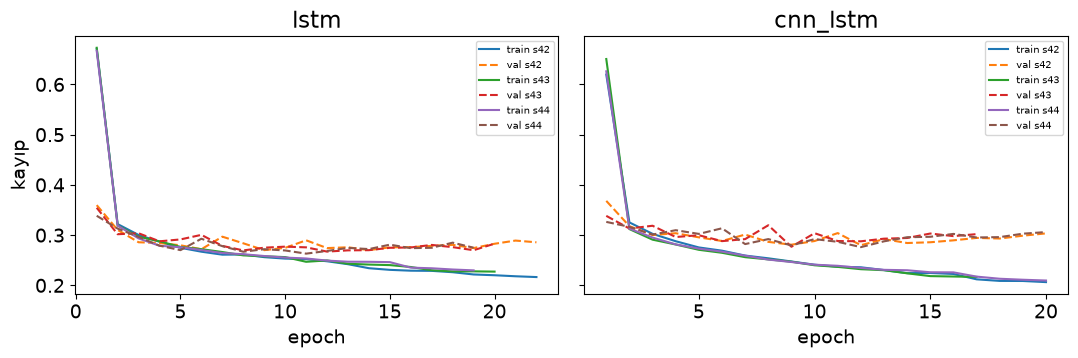

In [4]:
t = pd.DataFrame([{'model': k[0], 'seed': k[1], 'best_epoch': h['best_epoch'], 'stopped_epoch': h['stopped_epoch'],
  'best_val_loss': round(h['best_val_loss'], 4), 'total_sec': round(h['total_sec'], 1)} for k, h in hist.items()])
print(t.to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, name in zip(ax, ('lstm', 'cnn_lstm')):
    for (m, s), h in hist.items():
        if m != name: continue
        e = [x['epoch'] for x in h['epochs']]
        a.plot(e, [x['train_loss'] for x in h['epochs']], label=f'train s{s}')
        a.plot(e, [x['val_loss'] for x in h['epochs']], '--', label=f'val s{s}')
    a.set_title(name); a.set_xlabel('epoch'); a.legend(fontsize=7)
ax[0].set_ylabel('kayıp'); plt.tight_layout(); plt.show()

## 4. Test sonuçları (ortalama ± std)
Baseline'lar tek koşudur (std = 0); DL için 3 seed. Birincil metrik gündüz-yalnız RMSE (W).

In [5]:
s = pd.read_csv(config.METRICS_DIR / 'summary.csv')
d = s[s['mask'] == 'day'].copy()
d['RMSE_W'] = d.apply(lambda r: f"{r['RMSE_W_mean']:.1f} ± {r['RMSE_W_std']:.1f}", axis=1)
d['nRMSE'] = d.apply(lambda r: f"{r['nRMSE_mean']:.4f} ± {r['nRMSE_std']:.4f}", axis=1)
print(d.pivot(index='model', columns='scope', values='RMSE_W').to_string())
print()
print(d.pivot(index='model', columns='scope', values='nRMSE').to_string())

scope                          h4       mean16
model                                         
cnn_lstm              137.9 ± 2.5  154.5 ± 0.8
linreg                148.2 ± 0.0  172.2 ± 0.0
lstm                  136.9 ± 0.8  154.1 ± 0.3
persistence           197.2 ± 0.0  304.6 ± 0.0
seasonal_persistence  246.9 ± 0.0  246.9 ± 0.0
xgboost               134.0 ± 0.0  155.2 ± 0.0

scope                              h4           mean16
model                                                 
cnn_lstm              0.1379 ± 0.0025  0.1545 ± 0.0008
linreg                0.1482 ± 0.0000  0.1722 ± 0.0000
lstm                  0.1369 ± 0.0008  0.1541 ± 0.0003
persistence           0.1972 ± 0.0000  0.3046 ± 0.0000
seasonal_persistence  0.2469 ± 0.0000  0.2469 ± 0.0000
xgboost               0.1340 ± 0.0000  0.1552 ± 0.0000


## 5. Dürüstlük kontrolü
Sonuç ne olursa olsun gizlenmez; ayrıntılı yorum Faz 4'te yapılacaktır.

In [6]:
g = s[(s['mask']=='day')&(s['scope']=='h4')].set_index('model')['RMSE_W_mean']
best_dl = g[['lstm','cnn_lstm']].idxmin()
print('En iyi DL modeli:', best_dl, round(g[best_dl], 1), 'W')
print('Persistence RMSE (day/h4):', round(g['persistence'], 1), 'W')
print('DL persistence geçiyor mu?', bool(g[best_dl] < g['persistence']), '| fark (W):', round(g['persistence'] - g[best_dl], 1))
print('XGBoost - en iyi DL farkı (W, + = DL daha iyi):', round(g['xgboost'] - g[best_dl], 1))

En iyi DL modeli: lstm 136.9 W
Persistence RMSE (day/h4): 197.2 W
DL persistence geçiyor mu? True | fark (W): 60.4
XGBoost - en iyi DL farkı (W, + = DL daha iyi): -2.9


## 6. Birim testi

In [7]:
r = subprocess.run([sys.executable, '-I', str(PROJECT_ROOT/'tests'/'test_models.py')], capture_output=True, text=True, encoding='utf-8', cwd=PROJECT_ROOT)
print(r.stdout); print(r.stderr[-500:])

OK test_cikis_sekli
OK test_cnn_ara_uzunluk
OK test_param_orani
OK test_build_model
TESTLER_TAMAM


